# NHANES 2015-2018 Exploratory Data Analysis

EDA for the hypertension biomarker project using helper functions from `src/eda_utils.py` and the preprocessing pipeline `src/preprocessing_pipeline.py`.

In [156]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure project root is on the Python path
PROJECT_ROOT = Path("/Users/khaledmazahreh/Documents/hypertension_trial").resolve()
if PROJECT_ROOT.as_posix() not in sys.path:
    sys.path.insert(0, PROJECT_ROOT.as_posix())
os.chdir(PROJECT_ROOT)

from src.eda_utils import (
    load_cycle_dataframe,
    load_merged_cycles,
    dataset_overview,
    missingness_table,
    class_balance,
    numeric_descriptives,
    correlation_matrix,
    list_panels,
)
from src.preprocessing_pipeline import build_preprocessed_dataset

In [157]:
feature_labels = {
    "HTN_13080": "Hypertension status",
    "RIDAGEYR": "Age",
    "RIAGENDR": "Sex",
    "RIDRETH3": "Race/ethnicity",
    "BMXBMI": "Body Mass Index",
    "BPXSY1": "Systolic BP #1",
    "BPXSY2": "Systolic BP #2",
    "BPXSY3": "Systolic BP #3",
    "BPXSY4": "Systolic BP #4",
    "BPXDI1": "Diastolic BP #1",
    "BPXDI2": "Diastolic BP #2",
    "BPXDI3": "Diastolic BP #3",
    "BPXDI4": "Diastolic BP #4",
    "SBP": "Mean systolic BP",
    "DBP": "Mean diastolic BP",
    "BPQ020": "Told hypertensive",
    "BPQ050A": "Takes HTN meds",
    "LBXSCR": "Serum creatinine",
    "LBXSBU": "Blood urea nitrogen",
    "LBXSUA": "Serum uric acid",
    "LBXSAL": "Serum albumin",
    "URXUMA": "Urine albumin",
    "URXUCR": "Urine creatinine",
    "ACR_mg_g": "Albumin/creatinine",
    "eGFR": "Estimated GFR",
    "LBXWBCSI": "White cell count",
    "LBXHGB": "Hemoglobin",
    "LBXHCT": "Hematocrit",
    "LBXPLTSI": "Platelet count",
    "LBXRDW": "Red cell width",
}

def label_name(code: str, wrap: bool = False) -> str:
    short = feature_labels.get(code, code)
    text = f"{code} ({short})"
    if wrap:
        return text.replace(" (", "\n(")
    return text



In [ ]:
import sys
import os
from pathlib import Path

# add project root to path
project_root = str(Path("..").resolve())
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

In [159]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path

from src.eda_utils import (
    load_cycle_dataframe,
    load_merged_cycles,
    dataset_overview,
    missingness_table,
    class_balance,
    numeric_descriptives,
    correlation_matrix,
    list_panels,
)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})



In [160]:
cycles = ['2015_2016', '2017_2018']
cycle_frames = {cycle: load_cycle_dataframe(cycle) for cycle in cycles}
merged = load_merged_cycles(cycles)
processed_dataset, feature_panels, scaler = build_preprocessed_dataset()


## 1. Dataset assembly



In [161]:
n_by_cycle = {c: df.shape[0] for c, df in cycle_frames.items()}
total_adults = merged.shape[0]
unique_ids = merged["SEQN"].nunique()
print("Participants per cycle:", n_by_cycle)
print("Total adults (>=20y):", total_adults)
print("Unique SEQN count:", unique_ids)



Participants per cycle: {'2015_2016': 5474, '2017_2018': 5265}
Total adults (>=20y): 10739
Unique SEQN count: 10739


In [162]:
duplicate_ids = merged["SEQN"].duplicated().sum()
duplicate_ids


np.int64(0)

In [163]:
overview = dataset_overview(merged)
overview.head()


,column,dtype,non_null,min,max,mean,median,missing_pct
0,ACR_mg_g,float64,10474,2.739726e-01,21152.173913,52.650677,7.589824,2.467641
1,BMXBMI,float64,10581,1.420000e+01,86.200000,29.693441,28.500000,1.471273
2,BPQ020,float64,10739,1.000000e+00,9.000000,1.636838,2.000000,0.000000
3,BPQ050A,float64,3610,1.000000e+00,2.000000,1.148753,1.000000,66.384207
4,BPXDI1,float64,9811,5.397605e-79,136.000000,70.937723,72.000000,8.641401


## 2. Missing-value analysis



In [164]:
missing_tbl = missingness_table(merged)
missing_tbl.head(10)


,missing,missing_pct
BPXDI4,10062,93.695875
BPXSY4,10062,93.695875
BPQ050A,7129,66.384207
BPXSY1,928,8.641401
BPXDI1,928,8.641401
LBXSUA,678,6.313437
LBXSBU,677,6.304125
eGFR,675,6.285501
LBXSCR,675,6.285501
LBXSAL,673,6.266878


/var/folders/vk/4m7_md257wg416ynxtlk0hdm0000gn/T/ipykernel_16392/3855683538.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_missing, x="missing_pct", y="label", palette="viridis")


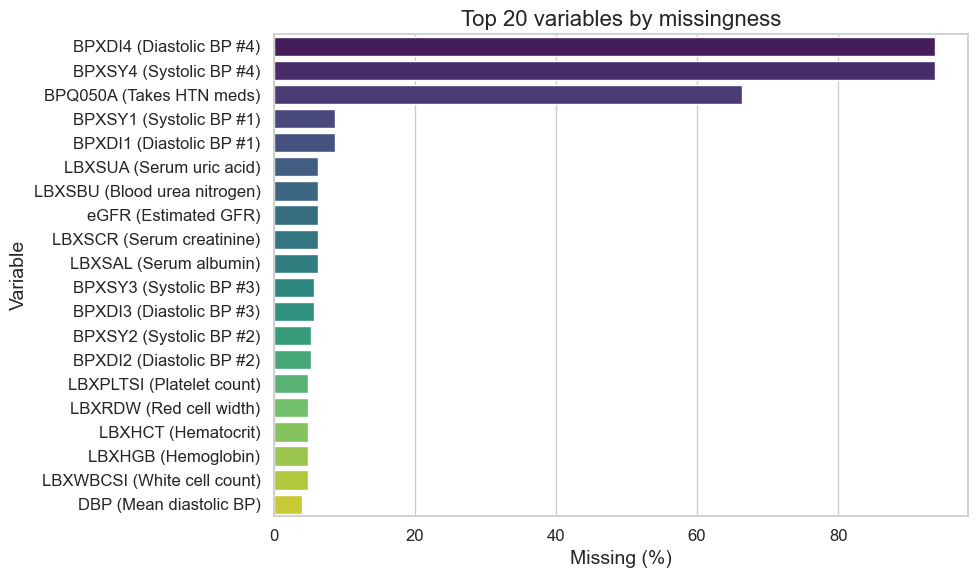

In [165]:
top_missing = missing_tbl.head(20).reset_index()
top_missing["label"] = top_missing["index"].apply(label_name)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_missing, x="missing_pct", y="label", palette="viridis")
plt.xlabel("Missing (%)")
plt.ylabel("Variable")
plt.title("Top 20 variables by missingness")
plt.tight_layout()



## 3. Outcome prevalence and class balance



In [166]:
balance = class_balance(merged)
balance


,HTN_13080,count,percent
0,1,6052,56.35534
1,0,4687,43.64466


/var/folders/vk/4m7_md257wg416ynxtlk0hdm0000gn/T/ipykernel_16392/1777051378.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=balance, x="status_label", y="percent", palette="pastel")


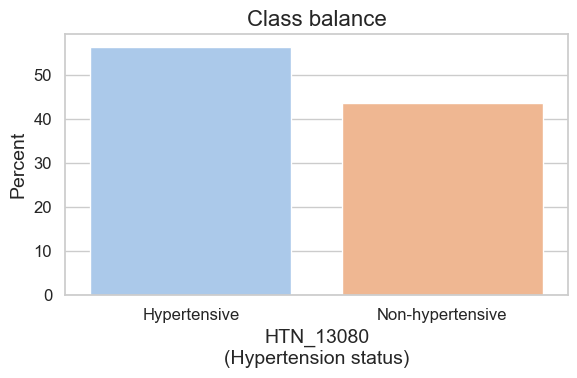

In [167]:
balance["status_label"] = balance["HTN_13080"].map({1: "Hypertensive", 0: "Non-hypertensive"})
plt.figure(figsize=(6, 4))
sns.barplot(data=balance, x="status_label", y="percent", palette="pastel")
plt.ylabel("Percent")
plt.xlabel(label_name("HTN_13080", wrap=True))
plt.title("Class balance")
plt.tight_layout()



## 4. Continuous-variable distributions



In [168]:
panels = list_panels()
numeric_cols = sorted({col for cols in panels.values() for col in cols if merged[col].dtype.kind in "if"})
desc = numeric_descriptives(merged, numeric_cols)
desc.head()


,column,count,mean,std,min,q1,median,q3,max,skew,kurtosis
0,ACR_mg_g,10474.0,52.650677,401.610492,0.273973,4.876033,7.589824,14.936098,21152.173913,26.174848,998.453728
1,BMXBMI,10581.0,29.693441,7.236030,14.200000,24.700000,28.500000,33.400000,86.200000,1.200179,2.718175
2,LBXHCT,10211.0,41.715425,4.247313,21.800000,39.100000,41.800000,44.600000,59.100000,-0.287010,0.822773
3,LBXHGB,10211.0,13.935354,1.555956,6.200000,13.000000,14.000000,15.000000,19.900000,-0.433441,1.017313
4,LBXPLTSI,10211.0,240.743316,63.277925,8.000000,199.000000,234.000000,275.000000,818.000000,0.890512,3.053983


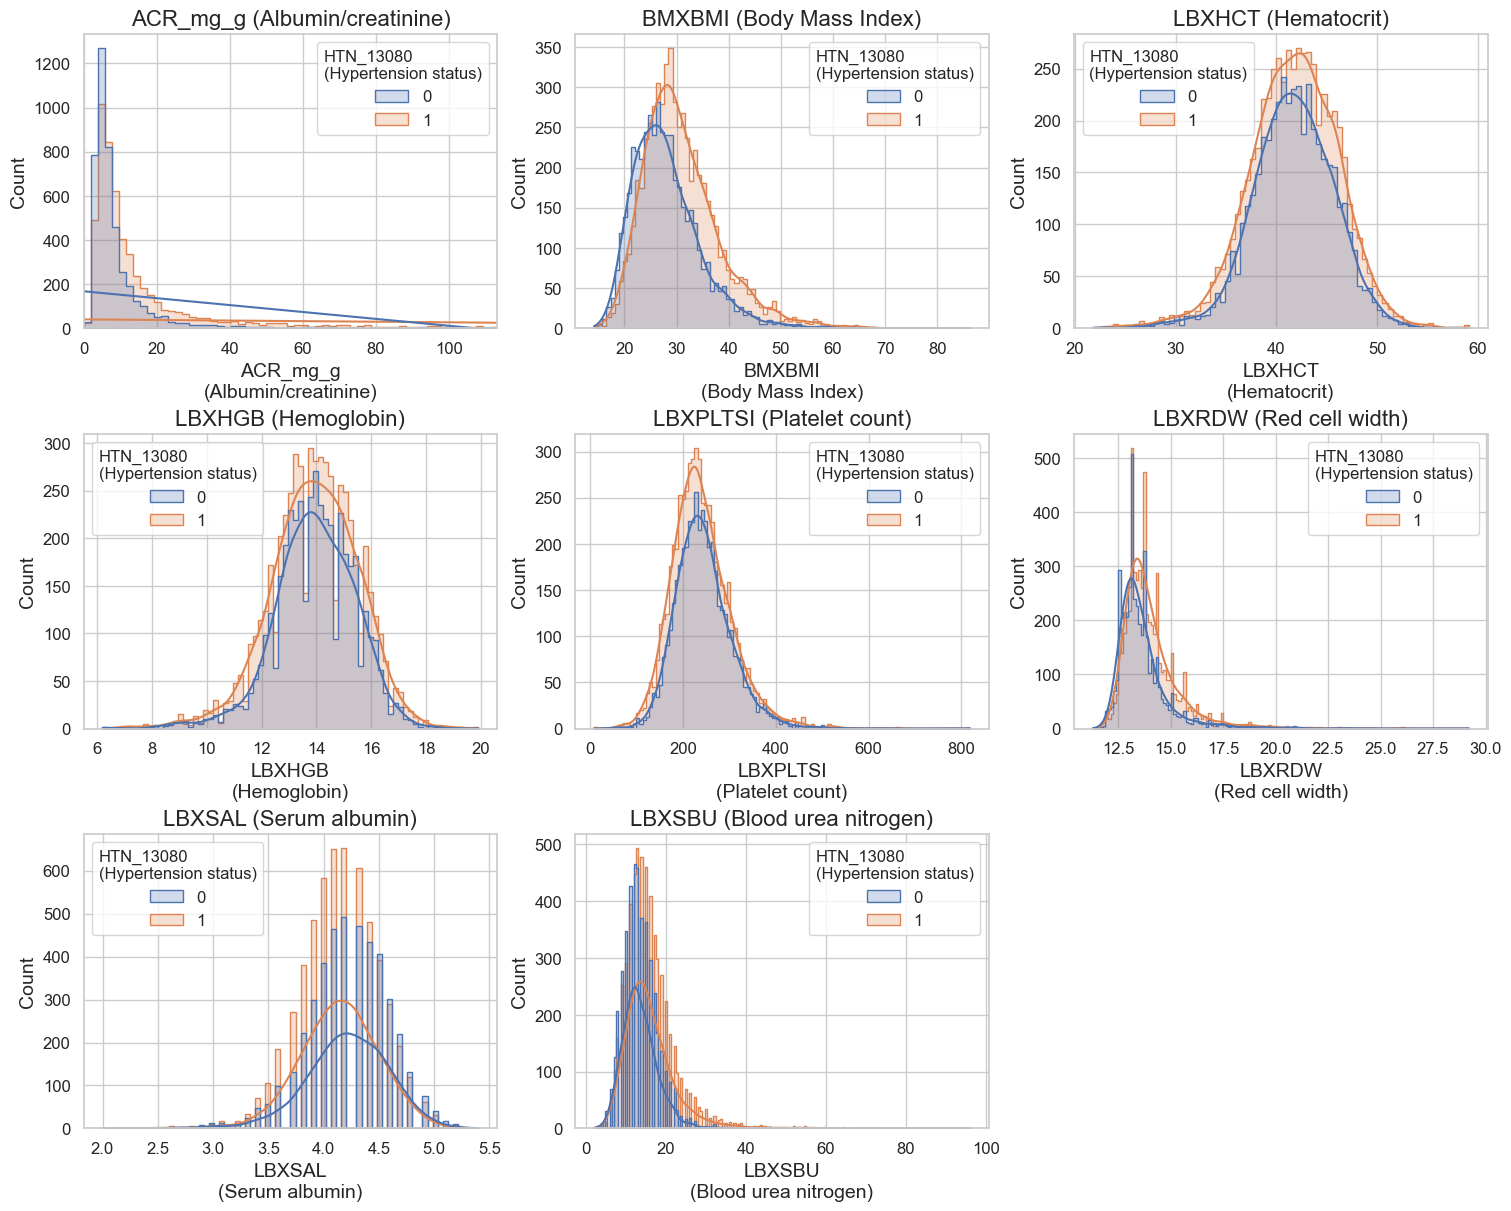

In [169]:
subset = numeric_cols[:8]
n_cols = 3
n_rows = int(np.ceil(len(subset) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows), constrained_layout=True)
axes = axes.flatten()
for ax, col in zip(axes, subset):
    if col == "ACR_mg_g":
        # Force bins within visible range to fix histogram appearance
        xlim = merged[col].quantile(0.95)
        bins = np.linspace(0, xlim, 60)
        sns.histplot(data=merged, x=col, hue="HTN_13080", kde=True, ax=ax, element="step", bins=bins)
        ax.set_xlim(0, xlim)
    else:
        sns.histplot(data=merged, x=col, hue="HTN_13080", kde=True, ax=ax, element="step")
    ax.set_title(label_name(col))
    ax.set_xlabel(label_name(col, wrap=True))
    ax.set_ylabel("Count")
    if ax.get_legend() is not None:
        ax.get_legend().set_title(label_name("HTN_13080", wrap=True))
for ax in axes[len(subset):]:
    ax.set_visible(False)
plt.show()

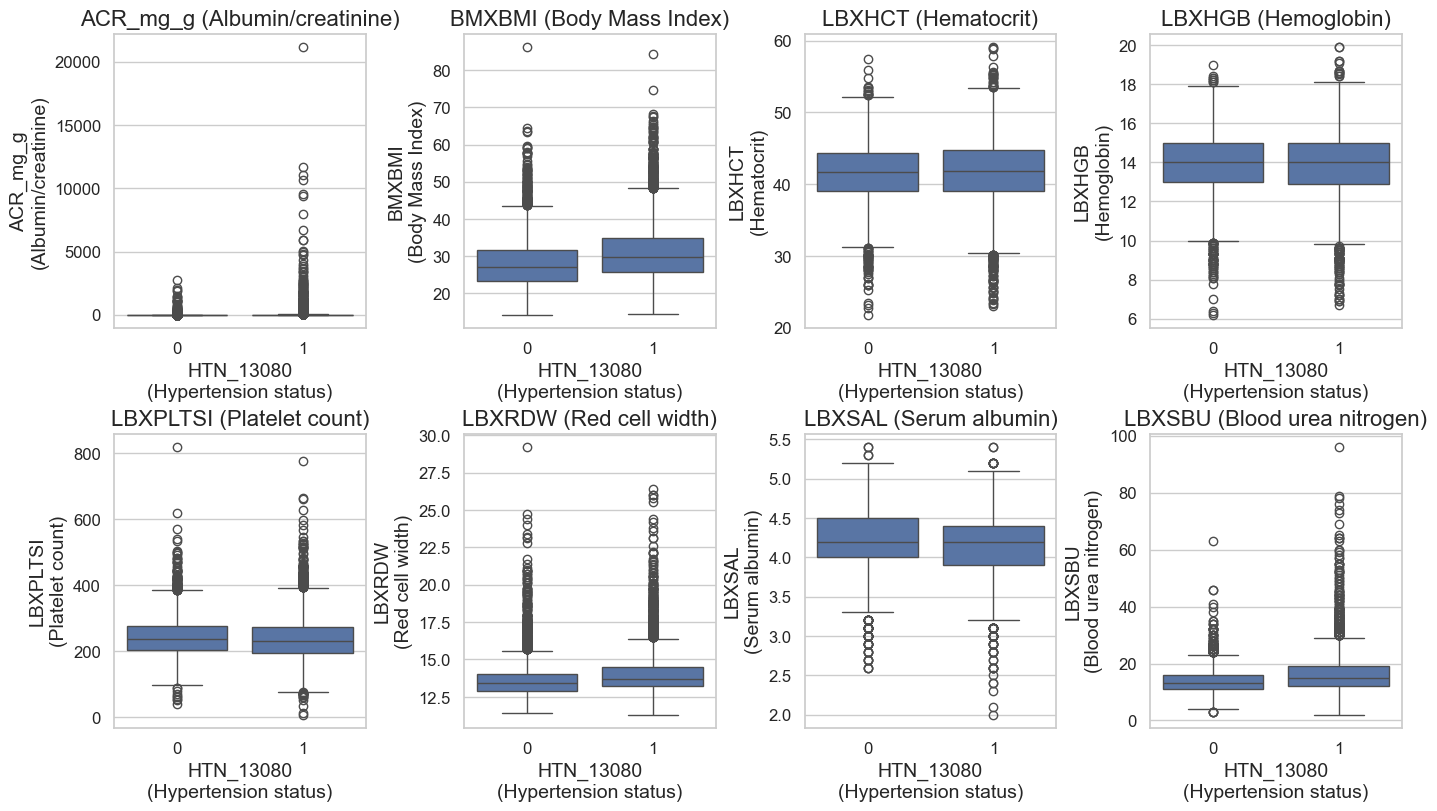

In [170]:
fig, axes = plt.subplots(2, int(np.ceil(len(subset)/2)), figsize=(14, 8), constrained_layout=True)
axes = axes.flatten()
for ax, col in zip(axes, subset):
    sns.boxplot(data=merged, x="HTN_13080", y=col, ax=ax)
    ax.set_xlabel(label_name("HTN_13080", wrap=True))
    ax.set_ylabel(label_name(col, wrap=True))
    ax.set_title(label_name(col))
plt.show()



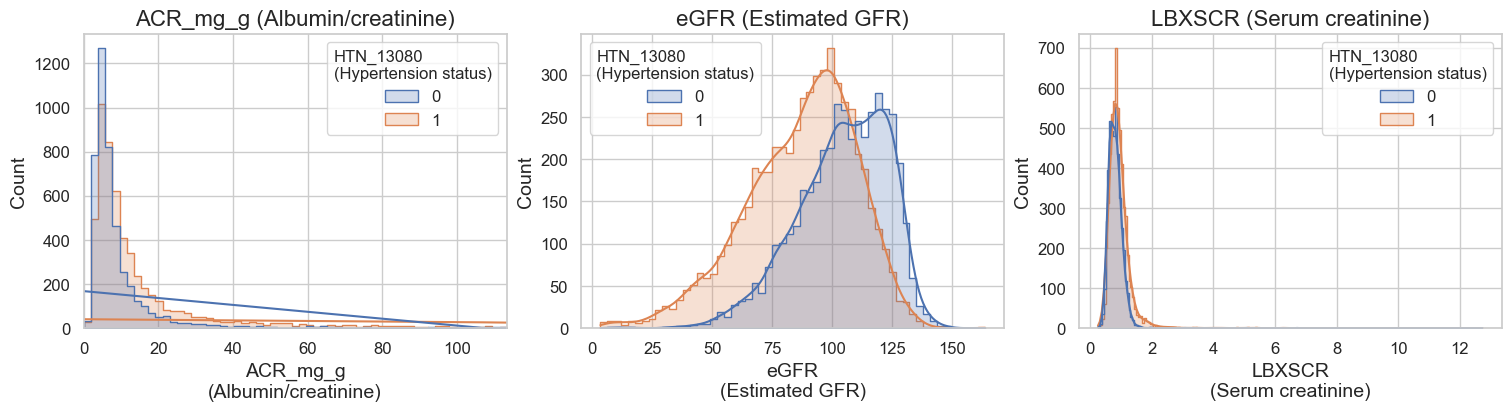

In [171]:
subset = ['ACR_mg_g', 'eGFR', 'LBXSCR']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

for ax, col in zip(axes, subset):
    if col == "ACR_mg_g":
        # Force bins within visible range to match ex2.pdf appearance
        xlim = merged[col].quantile(0.95)
        bins = np.linspace(0, xlim, 60)  # 60 bins from 0 to 95th percentile
        sns.histplot(data=merged, x=col, hue="HTN_13080", kde=True, ax=ax, 
                     element="step", bins=bins)
        ax.set_xlim(0, xlim)
    else:
        sns.histplot(data=merged, x=col, hue="HTN_13080", kde=True, ax=ax, element="step")
    
    ax.set_title(label_name(col))
    ax.set_xlabel(label_name(col, wrap=True))
    ax.set_ylabel("Count")
    if ax.get_legend() is not None:
        ax.get_legend().set_title(label_name("HTN_13080", wrap=True))

plt.show()

In [172]:
skewed = desc.loc[desc["skew"].abs() > 1, ["column", "skew"]]
skewed


,column,skew
0,ACR_mg_g,26.174848
1,BMXBMI,1.200179
5,LBXRDW,2.663378
7,LBXSBU,2.625476
8,LBXSCR,11.624443
10,LBXWBCSI,59.898428
14,URXUCR,1.291671
15,URXUMA,18.546901


## 5. Categorical summaries



In [173]:
categorical_cols = ["RIAGENDR", "RIDRETH3"]
category_maps = {
    "RIAGENDR": {1: "Male", 2: "Female"},
    "RIDRETH3": {
        1: "Mexican American",
        2: "Other Hispanic",
        3: "Non-Hispanic White",
        4: "Non-Hispanic Black",
        6: "Non-Hispanic Asian",
        7: "Other race"
    }
}

def map_categories(series, mapping):
    return series.apply(lambda x: mapping.get(int(x), mapping.get(x, x)) if pd.notna(x) else x)

cat_summary = {}
for col in categorical_cols:
    mapped = map_categories(merged[col], category_maps.get(col, {}))
    cat_summary[col] = mapped.value_counts(normalize=True).mul(100).round(2)
cat_summary


{'RIAGENDR': RIAGENDR
 Female    51.9
 Male      48.1
 Name: proportion, dtype: float64,
 'RIDRETH3': RIDRETH3
 Non-Hispanic White    33.50
 Non-Hispanic Black    22.36
 Mexican American      15.36
 Non-Hispanic Asian    13.11
 Other Hispanic        11.35
 Other race             4.32
 Name: proportion, dtype: float64}

/var/folders/vk/4m7_md257wg416ynxtlk0hdm0000gn/T/ipykernel_16392/352627707.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
/var/folders/vk/4m7_md257wg416ynxtlk0hdm0000gn/T/ipykernel_16392/352627707.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


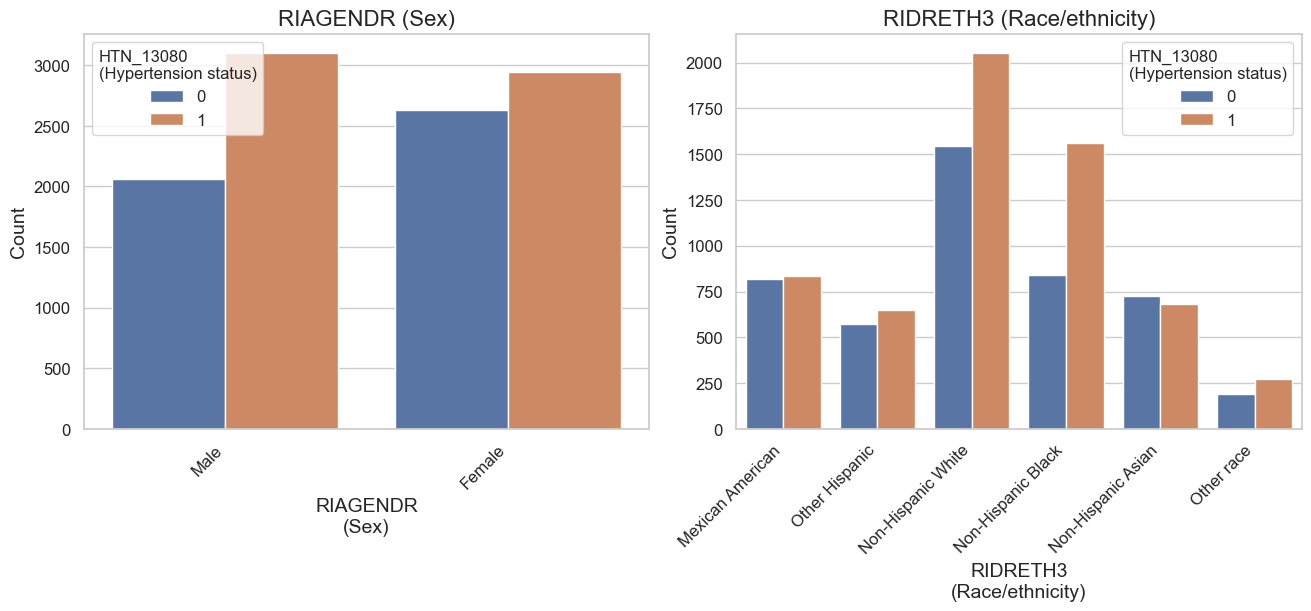

In [174]:
fig, axes = plt.subplots(1, len(categorical_cols), figsize=(13, 6), constrained_layout=True)
for ax, col in zip(axes, categorical_cols):
    data = merged.copy()
    categories = category_maps.get(col, {})
    if categories:
        data[col] = map_categories(data[col], categories)
        order = [categories[k] for k in categories if categories[k] in data[col].unique()]
    else:
        order = sorted(data[col].dropna().unique())
    sns.countplot(data=data, x=col, hue="HTN_13080", order=order, ax=ax)
    ax.set_title(label_name(col))
    ax.set_xlabel(label_name(col, wrap=True))
    ax.set_ylabel("Count")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
    if ax.get_legend() is not None:
        ax.get_legend().set_title(label_name("HTN_13080", wrap=True))
plt.show()


In [175]:
import pandas as pd

#!pip install statsmodels
from statsmodels.stats.proportion import proportion_confint

def prevalence_table(df, category, mapping):
    mapped = map_categories(df[category], mapping)
    groups = df.assign(category=mapped).groupby("category", dropna=False)
    rows = []
    for name, grp in groups:
        n_total = len(grp)
        if n_total == 0:
            continue
        n_htn = grp["HTN_13080"].sum()
        prev = n_htn / n_total
        ci_low, ci_high = proportion_confint(n_htn, n_total, alpha=0.05, method="wilson")
        rows.append({
            "Category": category,
            "Group": name,
            "n_total": n_total,
            "n_HTN": int(n_htn),
            "Prevalence (%)": prev * 100,
            "CI_low (%)": ci_low * 100,
            "CI_high (%)": ci_high * 100
        })
    return pd.DataFrame(rows)

sex_table = prevalence_table(merged, "RIAGENDR", category_maps["RIAGENDR"])
race_table = prevalence_table(merged, "RIDRETH3", category_maps["RIDRETH3"])
prevalence_summary = pd.concat([sex_table, race_table], ignore_index=True)
prevalence_summary

,Category,Group,n_total,n_HTN,Prevalence (%),CI_low (%),CI_high (%)
0,RIAGENDR,Female,5574,2947,52.870470,51.558501,54.178485
1,RIAGENDR,Male,5165,3105,60.116167,58.773737,61.443560
2,RIDRETH3,Mexican American,1649,833,50.515464,48.103919,52.924612
3,RIDRETH3,Non-Hispanic Asian,1408,680,48.295455,45.693499,50.906686
4,RIDRETH3,Non-Hispanic Black,2401,1561,65.014577,63.084307,66.896880
5,RIDRETH3,Non-Hispanic White,3598,2055,57.115064,55.491189,58.723762
6,RIDRETH3,Other Hispanic,1219,649,53.240361,50.433636,56.026728
7,RIDRETH3,Other race,464,274,59.051724,54.520907,63.433893


## 6. Correlation structure



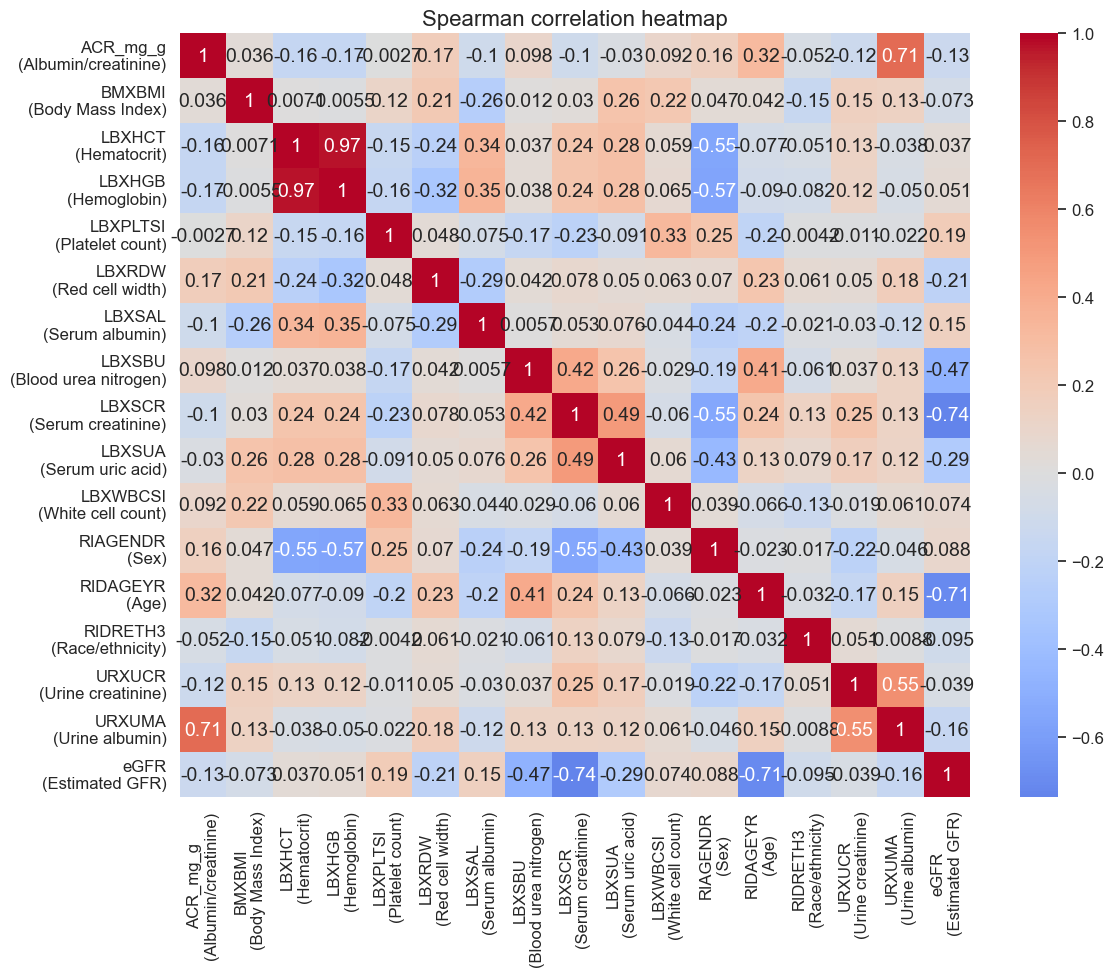

In [176]:
corr = correlation_matrix(merged[numeric_cols])
plt.figure(figsize=(12, 10))
ax = sns.heatmap(corr, cmap="coolwarm", center=0, annot =True)
ax.set_xticklabels([label_name(c, wrap=True) for c in corr.columns], rotation=90)
ax.set_yticklabels([label_name(c, wrap=True) for c in corr.columns], rotation=0)
plt.title("Spearman correlation heatmap")
plt.tight_layout()



In [177]:
print(corr)

          ACR_mg_g    BMXBMI    LBXHCT    LBXHGB  LBXPLTSI    LBXRDW  \
ACR_mg_g  1.000000  0.035622 -0.164069 -0.170814 -0.002735  0.172496   
BMXBMI    0.035622  1.000000  0.007060 -0.005509  0.115269  0.213859   
LBXHCT   -0.164069  0.007060  1.000000  0.966410 -0.152695 -0.240027   
LBXHGB   -0.170814 -0.005509  0.966410  1.000000 -0.163851 -0.323347   
LBXPLTSI -0.002735  0.115269 -0.152695 -0.163851  1.000000  0.048362   
LBXRDW    0.172496  0.213859 -0.240027 -0.323347  0.048362  1.000000   
LBXSAL   -0.104689 -0.260015  0.339145  0.351167 -0.075126 -0.288633   
LBXSBU    0.097798  0.011913  0.037405  0.037949 -0.171954  0.042352   
LBXSCR   -0.100814  0.029531  0.244814  0.243214 -0.225046  0.077938   
LBXSUA   -0.030118  0.256398  0.278066  0.276937 -0.091243  0.050237   
LBXWBCSI  0.091691  0.224123  0.058898  0.065014  0.330935  0.063280   
RIAGENDR  0.156453  0.046597 -0.554005 -0.565540  0.246425  0.069935   
RIDAGEYR  0.316118  0.042166 -0.076889 -0.089908 -0.196496  0.23

In [178]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = (
    upper.stack()
    .reset_index()
    .rename(columns={0: "corr", "level_0": "var1", "level_1": "var2"})
)
high_corr = high_corr.loc[high_corr["corr"].abs() >= 0.8]
high_corr


,var1,var2,corr
31,LBXHCT,LBXHGB,0.96641


## 7. Processed dataset summary

Run the full preprocessing pipeline and confirm final sample size and panel definitions.

In [179]:
from src.preprocessing_pipeline import build_preprocessed_dataset

# Run the full preprocessing workflow (2015–2016 + 2017–2018)
dataset, panels, scaler = build_preprocessed_dataset()

print("Processed dataset shape:", dataset.shape)
display(dataset.head())

print("Feature panels (count of columns):")
for name, cols in panels.items():
    print(f"  {name}: {len(cols)} features")

Processed dataset shape: (10335, 48)


,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,WTMEC2YR,RIDEXPRG,BPQ020,BPQ030,BPQ040A,BPQ050A,BPXSY1,BPXSY2,BPXSY3,BPXSY4,BPXDI1,BPXDI2,BPXDI3,BPXDI4,LBXWBCSI,LBXHGB,LBXHCT,LBXPLTSI,LBXRDW,LBXSCR,LBXSBU,LBXSUA,LBXSAL,URXUMA,URXUCR,BMXBMI,SBP,DBP,HTN_self,HTN_meds,HTN_13080,eGFR,ACR_mg_g,cycle,ACR_mg_g_log,LBXSCR_log,sex_female,RIDRETH3_label,race_mexican_american,race_non_hispanic_asian,race_non_hispanic_black,race_non_hispanic_white,race_other_hispanic,race_other_race
0,83732.0,0.632015,1.0,3.0,135629.507405,NaN,2.0,NaN,NaN,NaN,128.0,124.0,116.0,NaN,70.0,64.0,62.0,NaN,1.406465,0.925071,0.795484,-1.103620,0.132321,0.169398,-0.379500,-0.973425,1.350566,-0.596078,-1.133223,-0.267923,-0.197978,-0.463855,0,0,0,0.097454,-0.350651,2015_2016,-0.511539,0.225544,0,non_hispanic_white,0,0,0,1,0,0
1,83733.0,0.117613,1.0,3.0,25282.425927,NaN,2.0,NaN,NaN,NaN,146.0,140.0,134.0,NaN,88.0,88.0,82.0,NaN,0.042655,1.765597,1.798293,-1.313133,-0.379751,0.898947,-1.053793,1.247175,1.024160,0.133459,0.802621,0.214664,0.702416,1.153333,0,0,1,-0.469013,-0.167736,2015_2016,0.237539,0.927057,0,non_hispanic_white,0,0,0,1,0,0
2,83734.0,1.546507,1.0,3.0,12575.838818,NaN,1.0,1.0,1.0,1.0,138.0,132.0,136.0,NaN,46.0,44.0,46.0,NaN,-1.539365,-1.214451,-1.098710,-0.303659,0.951636,1.239404,2.317670,1.485096,1.024160,3.016363,-0.732226,-0.107061,0.460003,-2.028876,1,1,1,-1.323826,3.566220,2015_2016,2.926369,1.237038,0,non_hispanic_white,0,0,0,1,0,0
3,83735.0,0.289080,2.0,3.0,102078.634508,NaN,2.0,NaN,NaN,NaN,132.0,134.0,136.0,NaN,72.0,68.0,70.0,NaN,-0.611974,-0.908805,-0.485882,0.782001,-0.686994,0.461217,-0.379500,-0.021739,-1.260682,-0.479775,-0.289748,2.080667,0.390742,-0.098684,0,0,1,-1.217324,-0.361846,2015_2016,-0.578659,0.512577,1,non_hispanic_white,0,0,0,1,0,0
4,83737.0,1.203572,2.0,1.0,10878.684022,NaN,2.0,NaN,NaN,NaN,116.0,122.0,120.0,NaN,58.0,58.0,60.0,NaN,-0.611974,-0.450336,-0.346603,-1.655973,0.337150,1.385314,2.317670,-0.418275,-0.281464,-0.317656,-0.815191,-0.139233,-0.371130,-0.985529,0,0,0,-2.129695,-0.074312,2015_2016,0.487004,1.366766,1,mexican_american,1,0,0,0,0,0


Feature panels (count of columns):
  PanelA_RenalDemo: 17 features
  PanelB_CBC: 13 features
  PanelC_Combined: 21 features


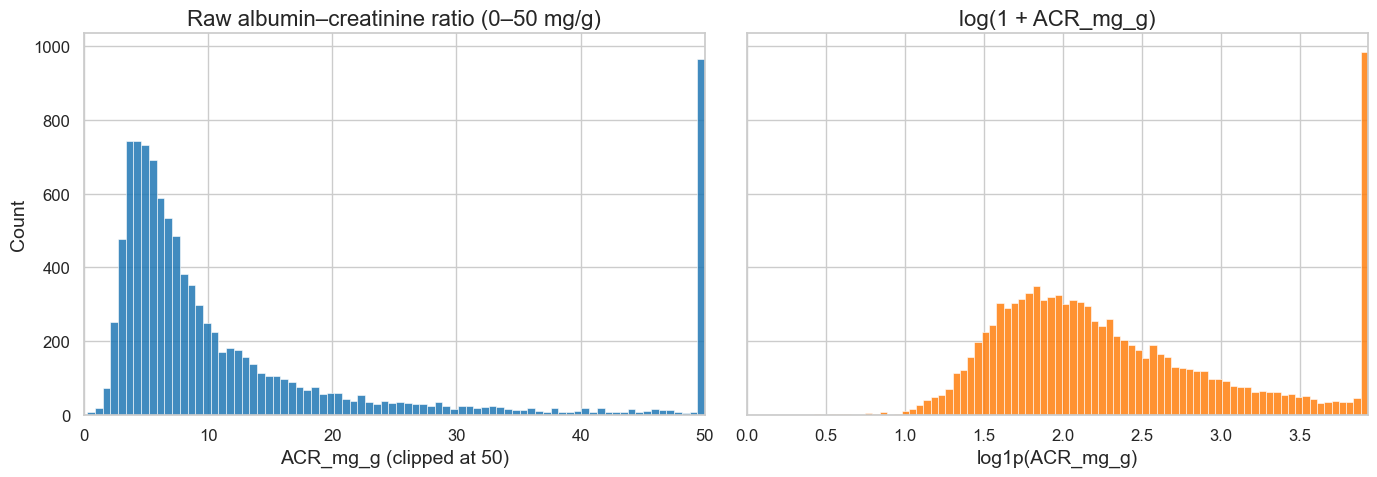

In [180]:
acr_raw = merged["ACR_mg_g"].dropna()
acr_log = np.log1p(acr_raw)

# Clip raw distribution at 50 mg/g for readability
raw_ylim = (0, 50)
log_xlim = (0, acr_log.quantile(0.99))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.histplot(acr_raw.clip(*raw_ylim), bins=80, ax=axes[0],
             color="#1f77b4", alpha=0.85)
axes[0].set_title("Raw albumin–creatinine ratio (0–50 mg/g)")
axes[0].set_xlabel("ACR_mg_g (clipped at 50)")
axes[0].set_ylabel("Count")
axes[0].set_xlim(raw_ylim)

sns.histplot(np.log1p(acr_raw.clip(*raw_ylim)), bins=80, ax=axes[1],
             color="#ff7f0e", alpha=0.85)
axes[1].set_title("log(1 + ACR_mg_g)")
axes[1].set_xlabel("log1p(ACR_mg_g)")
axes[1].set_xlim(0, np.log1p(raw_ylim[1]))

plt.tight_layout()
plt.show()


## 8. Post-processing validation

Verify that log transforms reduce skewness and inspect transformed distributions.

In [181]:
skew_table = pd.DataFrame([
      {
          'Variable': 'ACR_mg_g',
          'Raw skew': merged['ACR_mg_g'].skew(),
          'Transformed skew': processed_dataset['ACR_mg_g_log'].skew()
      },
      {
          'Variable': 'LBXSCR',
          'Raw skew': merged['LBXSCR'].skew(),
          'Transformed skew': processed_dataset['LBXSCR_log'].skew()
      },
  ])

skew_table['Reduction (%)'] = 100 * (1 - skew_table['Transformed skew'].abs() / skew_table['Raw skew'].abs())

skew_table

,Variable,Raw skew,Transformed skew,Reduction (%)
0,ACR_mg_g,26.174848,1.385806,94.705583
1,LBXSCR,11.624443,0.312445,97.312170


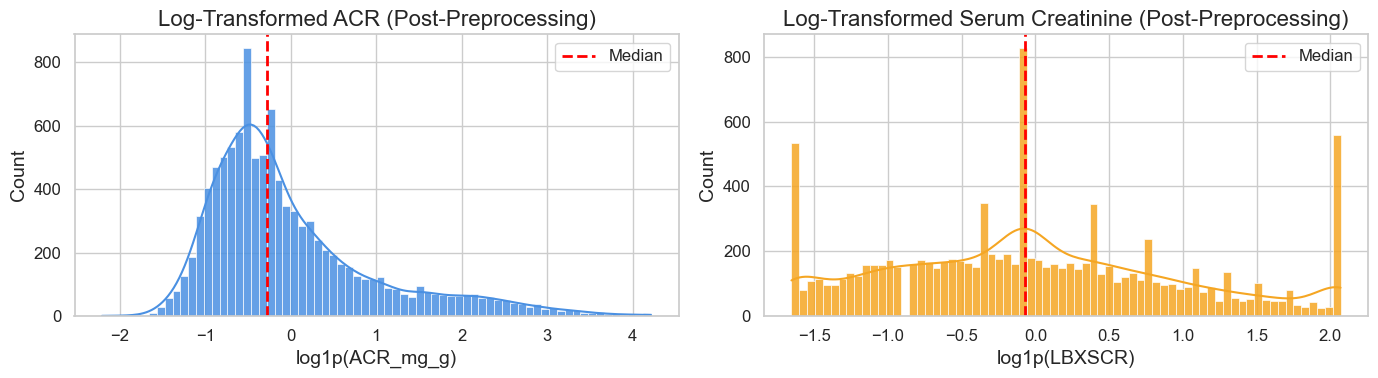

In [182]:
acr_log = processed_dataset['ACR_mg_g_log']
creat_log = processed_dataset['LBXSCR_log']
acr_median = acr_log.median()
creat_median = creat_log.median()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(acr_log, bins=70, color='#4A90E2', edgecolor='white', alpha=0.85, ax=axes[0], kde=True)
axes[0].axvline(acr_median, color='red', linestyle='--', linewidth=2, label='Median')
axes[0].set_title('Log-Transformed ACR (Post-Preprocessing)')
axes[0].set_xlabel('log1p(ACR_mg_g)')
axes[0].set_ylabel('Count')
axes[0].legend(frameon=True)

sns.histplot(creat_log, bins=70, color='#F5A623', edgecolor='white', alpha=0.85, ax=axes[1], kde=True)
axes[1].axvline(creat_median, color='red', linestyle='--', linewidth=2, label='Median')
axes[1].set_title('Log-Transformed Serum Creatinine (Post-Preprocessing)')
axes[1].set_xlabel('log1p(LBXSCR)')
axes[1].set_ylabel('Count')
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

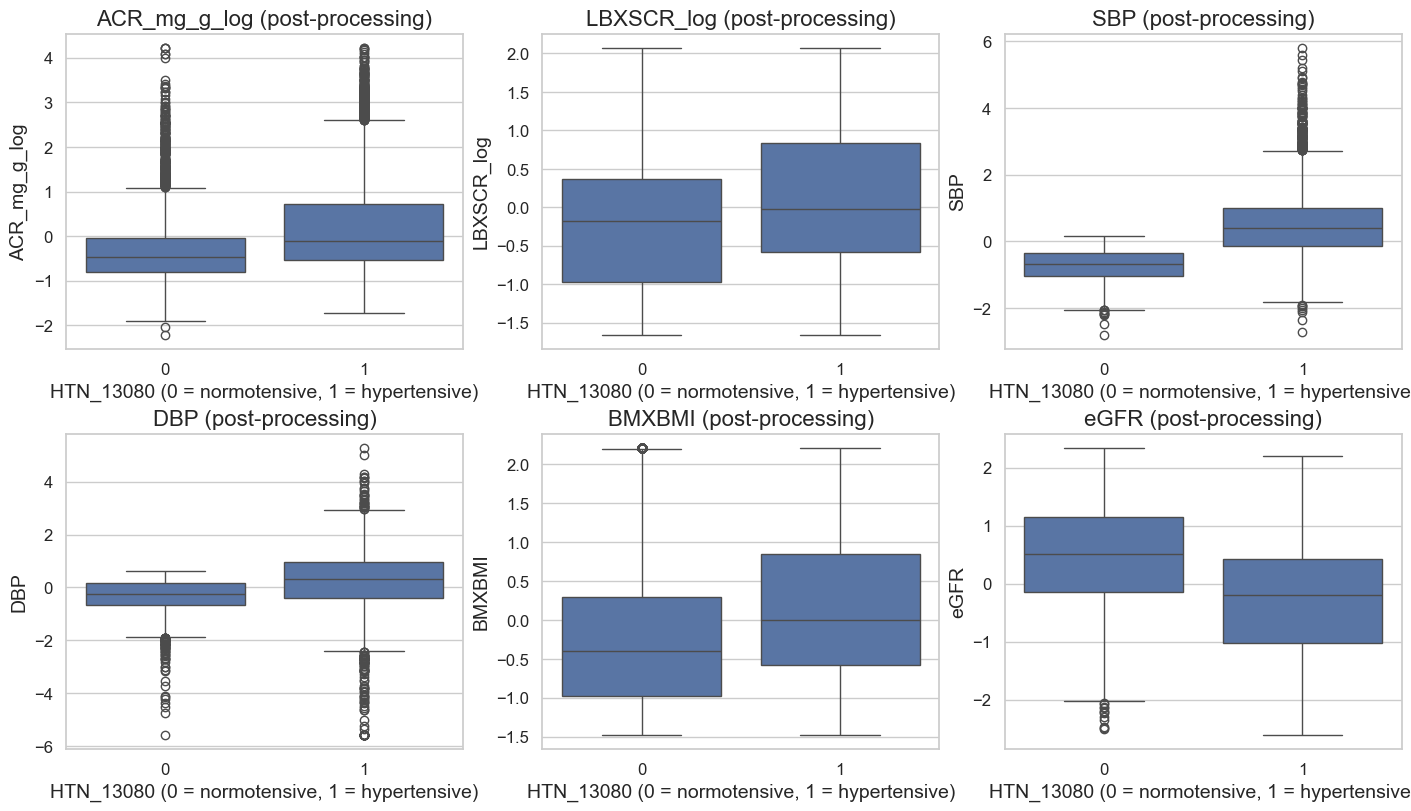

In [183]:
# Boxplots of transformed features after preprocessing
processed_box_cols = ["ACR_mg_g_log", "LBXSCR_log", "SBP", "DBP",
                      "BMXBMI", "eGFR"]
rows = 2
cols = int(np.ceil(len(processed_box_cols) / rows))

fig, axes = plt.subplots(rows, cols, figsize=(14, 8),
                         constrained_layout=True)
axes = axes.flatten()

for ax, col in zip(axes, processed_box_cols):
    sns.boxplot(data=processed_dataset, x="HTN_13080", y=col, ax=ax)
    ax.set_xlabel("HTN_13080 (0 = normotensive, 1 = hypertensive)")
    ax.set_ylabel(col)
    ax.set_title(f"{col} (post-processing)")

for ax in axes[len(processed_box_cols):]:
    ax.set_visible(False)

plt.show()


In [184]:
processed_dataset.columns

Index(['SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'WTMEC2YR', 'RIDEXPRG',
       'BPQ020', 'BPQ030', 'BPQ040A', 'BPQ050A', 'BPXSY1', 'BPXSY2', 'BPXSY3',
       'BPXSY4', 'BPXDI1', 'BPXDI2', 'BPXDI3', 'BPXDI4', 'LBXWBCSI', 'LBXHGB',
       'LBXHCT', 'LBXPLTSI', 'LBXRDW', 'LBXSCR', 'LBXSBU', 'LBXSUA', 'LBXSAL',
       'URXUMA', 'URXUCR', 'BMXBMI', 'SBP', 'DBP', 'HTN_self', 'HTN_meds',
       'HTN_13080', 'eGFR', 'ACR_mg_g', 'cycle', 'ACR_mg_g_log', 'LBXSCR_log',
       'sex_female', 'RIDRETH3_label', 'race_mexican_american',
       'race_non_hispanic_asian', 'race_non_hispanic_black',
       'race_non_hispanic_white', 'race_other_hispanic', 'race_other_race'],
      dtype='object')

## 9. Key takeaways

- Consolidated 2015-2018 NHANES cohort: 10,739 adults (51.9% female, 48.1% male), no duplicate SEQNs
- Hypertension prevalence: 56.4% (moderate class imbalance)
- ACR and serum creatinine are heavily right-skewed; log1p transform reduces skewness by >90%
- eGFR is approximately normal and kept on its original scale
- Strong correlations: eGFR/creatinine (r=-0.74), haemoglobin/haematocrit (r=0.97)
- Three feature panels defined for modelling: Panel A (renal), Panel B (CBC), Panel C (combined)

In [185]:
import importlib
from src import preprocessing_pipeline
importlib.reload(preprocessing_pipeline)
from src.preprocessing_pipeline import build_preprocessed_dataset

# Build the final processed dataset
processed_dataset, feature_panels, scaler = build_preprocessed_dataset()

print("="*60)
print("STEP 1: DATASET OVERVIEW")
print("="*60)
print(f"Shape: {processed_dataset.shape}")
print(f"Total samples: {len(processed_dataset)}")
print(f"Total features: {processed_dataset.shape[1]}")
print(f"\nColumns:\n{list(processed_dataset.columns)}")

STEP 1: DATASET OVERVIEW
Shape: (10335, 48)
Total samples: 10335
Total features: 48

Columns:
['SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'WTMEC2YR', 'RIDEXPRG', 'BPQ020', 'BPQ030', 'BPQ040A', 'BPQ050A', 'BPXSY1', 'BPXSY2', 'BPXSY3', 'BPXSY4', 'BPXDI1', 'BPXDI2', 'BPXDI3', 'BPXDI4', 'LBXWBCSI', 'LBXHGB', 'LBXHCT', 'LBXPLTSI', 'LBXRDW', 'LBXSCR', 'LBXSBU', 'LBXSUA', 'LBXSAL', 'URXUMA', 'URXUCR', 'BMXBMI', 'SBP', 'DBP', 'HTN_self', 'HTN_meds', 'HTN_13080', 'eGFR', 'ACR_mg_g', 'cycle', 'ACR_mg_g_log', 'LBXSCR_log', 'sex_female', 'RIDRETH3_label', 'race_mexican_american', 'race_non_hispanic_asian', 'race_non_hispanic_black', 'race_non_hispanic_white', 'race_other_hispanic', 'race_other_race']


In [186]:
processed_dataset.describe()

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,WTMEC2YR,RIDEXPRG,BPQ020,BPQ030,BPQ040A,BPQ050A,BPXSY1,BPXSY2,BPXSY3,BPXSY4,BPXDI1,BPXDI2,BPXDI3,BPXDI4,LBXWBCSI,LBXHGB,LBXHCT,LBXPLTSI,LBXRDW,LBXSCR,LBXSBU,LBXSUA,LBXSAL,URXUMA,URXUCR,BMXBMI,SBP,DBP,HTN_self,HTN_meds,HTN_13080,eGFR,ACR_mg_g,ACR_mg_g_log,LBXSCR_log,sex_female,race_mexican_american,race_non_hispanic_asian,race_non_hispanic_black,race_non_hispanic_white,race_other_hispanic,race_other_race
count,10335.000000,1.033500e+04,10335.000000,10335.000000,10335.000000,2070.000000,10335.000000,3994.000000,3994.000000,3604.000000,9693.000000,10048.000000,10009.000000,676.000000,9.693000e+03,1.004800e+04,1.000900e+04,6.760000e+02,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.019600e+04,1.019600e+04,10335.000000,10335.000000,10335.000000,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,10335.000000,10335.000000,10335.000000,10335.000000,10335.000000,10335.000000,10335.000000
mean,93369.965651,7.700124e-17,1.511950,3.364296,44173.297727,2.033816,1.623706,1.239860,1.104156,1.148169,126.414732,126.354896,125.892297,135.855030,7.107521e+01,7.118193e+01,7.112818e+01,7.639645e+01,5.500089e-17,-3.712560e-17,9.611405e-16,-2.131284e-16,-1.520775e-15,-5.390087e-16,-8.250133e-18,-3.135051e-16,-1.276021e-15,6.875111e-17,-2.200036e-17,-5.761343e-16,-6.745835e-16,-6.132578e-16,0.386454,0.297049,0.584228,-3.740060e-16,3.025049e-17,-2.447540e-16,-1.925031e-16,0.511950,0.152975,0.128108,0.223609,0.338945,0.112627,0.043735
std,5558.374929,1.000048e+00,0.499881,1.633529,46904.169775,0.180800,0.562143,0.715856,0.378045,0.355316,19.152053,19.477975,19.185326,23.511756,1.317531e+01,1.313017e+01,1.314597e+01,1.643617e+01,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000049e+00,1.000049e+00,0.486960,0.456980,0.492878,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,0.499881,0.359981,0.334227,0.416683,0.473374,0.316152,0.204515
min,83732.000000,-1.597059e+00,1.000000,1.000000,4579.581002,2.000000,1.000000,1.000000,1.000000,1.000000,72.000000,72.000000,72.000000,76.000000,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,-1.539365e+00,-1.902154e+00,-1.878672e+00,-1.655973e+00,-1.301479e+00,-1.532885e+00,-1.503321e+00,-1.607882e+00,-1.913493e+00,-6.277968e-01,-1.354462e+00,-1.474391e+00,-2.795268e+00,-5.576258e+00,0.000000,0.000000,0.000000,-2.604670e+00,-5.010662e-01,-2.206882e+00,-1.654111e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,88571.000000,-8.540346e-01,1.000000,2.000000,17049.257168,2.000000,1.000000,1.000000,1.000000,1.000000,114.000000,112.000000,112.000000,120.000000,6.400000e+01,6.400000e+01,6.400000e+01,6.800000e+01,-7.756311e-01,-6.795706e-01,-7.087285e-01,-7.226862e-01,-6.869935e-01,-7.546986e-01,-8.290286e-01,-7.355038e-01,-6.078698e-01,-5.220668e-01,-8.151911e-01,-7.665966e-01,-6.828052e-01,-5.681900e-01,0.000000,0.000000,0.000000,-6.897579e-01,-3.761350e-01,-6.706029e-01,-7.471596e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,93461.000000,6.045734e-02,2.000000,3.000000,26317.469800,2.000000,2.000000,1.000000,1.000000,1.000000,124.000000,124.000000,124.000000,134.000000,7.200000e+01,7.200000e+01,7.200000e+01,7.800000e+01,-1.210023e-01,8.132815e-03,1.552216e-02,-9.414603e-02,-2.773362e-01,-1.224222e-01,-1.547361e-01,-1.010466e-01,4.494200e-02,-3.669962e-01,-1.653006e-01,-1.392335e-01,-1.633471e-01,5.651124e-03,0.000000,0.000000,1.000000,1.051190e-01,-3.058266e-01,-2.769222e-01,-7.070016e-02,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,98161.500000,8.034820e-01,2.000000,4.000000,48201.818176,2.000000,2.000000,1.000000,1.000000,1.000000,136.000000,136.000000,136.000000,150.500000,7.800000e+01,7.800000e+01,7.800000e+01,8.600000e+01,6.427312e-01,7.722477e-01,7.397728e-01,6.296275e-01,4.395641e-01,6.071274e-

In [ ]:
# missing values check
missing = processed_dataset.isnull().sum()
missing_pct = (missing / len(processed_dataset)) * 100
missing_report = pd.DataFrame({'count': missing, 'pct': missing_pct})
missing_report = missing_report[missing_report['count'] > 0].sort_values('count', ascending=False)

if len(missing_report) == 0:
    print("No missing values in processed dataset")
else:
    print(f"Columns with missing values: {len(missing_report)}")
    print(missing_report)

In [ ]:
# feature panels check
for panel_name, cols in feature_panels.items():
    print(f"{panel_name}: {len(cols)} features")
    missing_cols = [c for c in cols if c not in processed_dataset.columns]
    if missing_cols:
        print(f"  MISSING: {missing_cols}")
    else:
        print(f"  All features present")

In [ ]:
# target integrity check
print(f"HTN_13080 missing: {processed_dataset['HTN_13080'].isnull().sum()}")
print(f"Value counts:\n{processed_dataset['HTN_13080'].value_counts()}")
print(f"Prevalence: {processed_dataset['HTN_13080'].mean():.1%}")

In [ ]:
# BPQ columns analysis
bpq_cols = ['BPQ020', 'BPQ030', 'BPQ040A', 'BPQ050A']
for col in bpq_cols:
    if col in processed_dataset.columns:
        print(f"\n{col}: {processed_dataset[col].value_counts().to_dict()}")

In [191]:
import importlib
from src import preprocessing_pipeline
importlib.reload(preprocessing_pipeline)
from src.preprocessing_pipeline import build_preprocessed_dataset

processed_dataset, feature_panels, scaler = build_preprocessed_dataset()

print("="*60)
print("VERIFICATION AFTER FIXES")
print("="*60)
print(f"Total samples: {len(processed_dataset)}")
print(f"\nHTN_13080 distribution:")
print(processed_dataset['HTN_13080'].value_counts())
print(f"\nRows with missing SBP: {processed_dataset['SBP'].isnull().sum()}")

# Verify no uncertain HTN status remains
uncertain = (
    processed_dataset['SBP'].isnull() & 
    (processed_dataset['HTN_self'] == 0) & 
    (processed_dataset['HTN_meds'] == 0)
)
print(f"Rows with uncertain HTN (should be 0): {uncertain.sum()}")

VERIFICATION AFTER FIXES
Total samples: 10335

HTN_13080 distribution:
HTN_13080
1    6038
0    4297
Name: count, dtype: int64

Rows with missing SBP: 139
Rows with uncertain HTN (should be 0): 0


In [ ]:
# final feature panel check
for panel_name, cols in feature_panels.items():
    present = [c for c in cols if c in processed_dataset.columns]
    print(f"{panel_name}: {len(present)}/{len(cols)} features present")

In [194]:
processed_dataset.describe()

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH3,WTMEC2YR,RIDEXPRG,BPQ020,BPQ030,BPQ040A,BPQ050A,BPXSY1,BPXSY2,BPXSY3,BPXSY4,BPXDI1,BPXDI2,BPXDI3,BPXDI4,LBXWBCSI,LBXHGB,LBXHCT,LBXPLTSI,LBXRDW,LBXSCR,LBXSBU,LBXSUA,LBXSAL,URXUMA,URXUCR,BMXBMI,SBP,DBP,HTN_self,HTN_meds,HTN_13080,eGFR,ACR_mg_g,ACR_mg_g_log,LBXSCR_log,sex_female,race_mexican_american,race_non_hispanic_asian,race_non_hispanic_black,race_non_hispanic_white,race_other_hispanic,race_other_race
count,10335.000000,1.033500e+04,10335.000000,10335.000000,10335.000000,2070.000000,10335.000000,3994.000000,3994.000000,3604.000000,9693.000000,10048.000000,10009.000000,676.000000,9.693000e+03,1.004800e+04,1.000900e+04,6.760000e+02,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,1.019600e+04,1.019600e+04,10335.000000,10335.000000,10335.000000,1.033500e+04,1.033500e+04,1.033500e+04,1.033500e+04,10335.000000,10335.000000,10335.000000,10335.000000,10335.000000,10335.000000,10335.000000
mean,93369.965651,7.700124e-17,1.511950,3.364296,44173.297727,2.033816,1.623706,1.239860,1.104156,1.148169,126.414732,126.354896,125.892297,135.855030,7.107521e+01,7.118193e+01,7.112818e+01,7.639645e+01,5.500089e-17,-3.712560e-17,9.611405e-16,-2.131284e-16,-1.520775e-15,-5.390087e-16,-8.250133e-18,-3.135051e-16,-1.276021e-15,6.875111e-17,-2.200036e-17,-5.761343e-16,-6.745835e-16,-6.132578e-16,0.386454,0.297049,0.584228,-3.740060e-16,3.025049e-17,-2.447540e-16,-1.925031e-16,0.511950,0.152975,0.128108,0.223609,0.338945,0.112627,0.043735
std,5558.374929,1.000048e+00,0.499881,1.633529,46904.169775,0.180800,0.562143,0.715856,0.378045,0.355316,19.152053,19.477975,19.185326,23.511756,1.317531e+01,1.313017e+01,1.314597e+01,1.643617e+01,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,1.000049e+00,1.000049e+00,0.486960,0.456980,0.492878,1.000048e+00,1.000048e+00,1.000048e+00,1.000048e+00,0.499881,0.359981,0.334227,0.416683,0.473374,0.316152,0.204515
min,83732.000000,-1.597059e+00,1.000000,1.000000,4579.581002,2.000000,1.000000,1.000000,1.000000,1.000000,72.000000,72.000000,72.000000,76.000000,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,-1.539365e+00,-1.902154e+00,-1.878672e+00,-1.655973e+00,-1.301479e+00,-1.532885e+00,-1.503321e+00,-1.607882e+00,-1.913493e+00,-6.277968e-01,-1.354462e+00,-1.474391e+00,-2.795268e+00,-5.576258e+00,0.000000,0.000000,0.000000,-2.604670e+00,-5.010662e-01,-2.206882e+00,-1.654111e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,88571.000000,-8.540346e-01,1.000000,2.000000,17049.257168,2.000000,1.000000,1.000000,1.000000,1.000000,114.000000,112.000000,112.000000,120.000000,6.400000e+01,6.400000e+01,6.400000e+01,6.800000e+01,-7.756311e-01,-6.795706e-01,-7.087285e-01,-7.226862e-01,-6.869935e-01,-7.546986e-01,-8.290286e-01,-7.355038e-01,-6.078698e-01,-5.220668e-01,-8.151911e-01,-7.665966e-01,-6.828052e-01,-5.681900e-01,0.000000,0.000000,0.000000,-6.897579e-01,-3.761350e-01,-6.706029e-01,-7.471596e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,93461.000000,6.045734e-02,2.000000,3.000000,26317.469800,2.000000,2.000000,1.000000,1.000000,1.000000,124.000000,124.000000,124.000000,134.000000,7.200000e+01,7.200000e+01,7.200000e+01,7.800000e+01,-1.210023e-01,8.132815e-03,1.552216e-02,-9.414603e-02,-2.773362e-01,-1.224222e-01,-1.547361e-01,-1.010466e-01,4.494200e-02,-3.669962e-01,-1.653006e-01,-1.392335e-01,-1.633471e-01,5.651124e-03,0.000000,0.000000,1.000000,1.051190e-01,-3.058266e-01,-2.769222e-01,-7.070016e-02,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,98161.500000,8.034820e-01,2.000000,4.000000,48201.818176,2.000000,2.000000,1.000000,1.000000,1.000000,136.000000,136.000000,136.000000,150.500000,7.800000e+01,7.800000e+01,7.800000e+01,8.600000e+01,6.427312e-01,7.722477e-01,7.397728e-01,6.296275e-01,4.395641e-01,6.071274e-

In [195]:
import pandas as pd

# Set pandas to show ALL rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

# Get all numeric columns
numeric_cols = processed_dataset.select_dtypes(include=['number']).columns.tolist()

print(f"Total numeric columns: {len(numeric_cols)}")
print("="*100)

# Descriptive statistics for ALL numeric columns
stats = processed_dataset[numeric_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
stats['missing'] = processed_dataset[numeric_cols].isnull().sum()
stats['missing_pct'] = (stats['missing'] / len(processed_dataset) * 100).round(2)
stats['skew'] = processed_dataset[numeric_cols].skew()

# Round for readability
stats = stats.round(3)

# Reorder columns
stats = stats[['count', 'missing', 'missing_pct', 'mean', 'std', 'min', '1%', '5%', '25%', '50%', '75%', '95%', '99%', 'max', 'skew']]

print(stats.to_string())

Total numeric columns: 46
                           count  missing  missing_pct       mean        std        min         1%         5%        25%        50%        75%         95%         99%         max   skew
SEQN                     10335.0        0         0.00  93369.966   5558.375  83732.000  83934.340  84695.700  88571.000  93461.000  98161.500  102030.300  102784.320  102956.000 -0.011
RIDAGEYR                 10335.0        0         0.00      0.000      1.000     -1.597     -1.597     -1.597     -0.854      0.060      0.803       1.661       1.661       1.661  0.013
RIAGENDR                 10335.0        0         0.00      1.512      0.500      1.000      1.000      1.000      1.000      2.000      2.000       2.000       2.000       2.000 -0.048
RIDRETH3                 10335.0        0         0.00      3.364      1.634      1.000      1.000      1.000      2.000      3.000      4.000       6.000       7.000       7.000  0.500
WTMEC2YR                 10335.0        0   

In [ ]:
# feature panel definitions
for panel_name, cols in feature_panels.items():
    print(f"\n{panel_name} ({len(cols)} features):")
    for c in sorted(cols):
        print(f"  {c}")

In [200]:
# Trace the data drops step by step
from src.preprocessing_pipeline import (
    read_paths_config, load_cycle_raw, merge_cycle, 
    screen_implausible, REQUIRED_KEYS
)
import pandas as pd

config = read_paths_config()

print("="*70)
print("DATA DROP ANALYSIS")
print("="*70)

total_dropped = 0

for cycle in ["2015_2016", "2017_2018"]:
    print(f"\n--- {cycle} ---")
    dfs = load_cycle_raw(config, cycle)
    
    # Initial merge (before exclusions)
    demo = dfs["DEMO"]
    print(f"1. DEMO file rows: {len(demo)}")
    
    # After all merges
    df = merge_cycle(
        dfs["DEMO"], dfs["BPQ"], dfs["BPX"], dfs["CBC"],
        dfs["BIOPRO"], dfs["ALB_CR"], dfs["BMX"]
    )
    # Note: merge_cycle already applies pregnancy and uncertain HTN exclusions
    print(f"2. After merge_cycle (adults, non-pregnant, certain HTN): {len(df)}")

# Let's trace more granularly
print("\n" + "="*70)
print("DETAILED DROP ANALYSIS")
print("="*70)

# Manual step-by-step trace
frames_raw = []
for cycle in ["2015_2016", "2017_2018"]:
    dfs = load_cycle_raw(config, cycle)
    
    # Simplified merge without exclusions
    keep_demo = ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDRETH3", "WTMEC2YR", "RIDEXPRG"]
    demo = dfs["DEMO"][[c for c in keep_demo if c in dfs["DEMO"].columns]].copy()
    
    df = (demo
          .merge(dfs["BPQ"][["SEQN", "BPQ020", "BPQ050A"]], on="SEQN", how="inner")
          .merge(dfs["BPX"], on="SEQN", how="inner")
          .merge(dfs["CBC"], on="SEQN", how="inner")
          .merge(dfs["BIOPRO"], on="SEQN", how="inner")
          .merge(dfs["ALB_CR"], on="SEQN", how="inner")
          .merge(dfs["BMX"], on="SEQN", how="inner"))
    
    frames_raw.append(df.assign(cycle=cycle))

combined_raw = pd.concat(frames_raw, ignore_index=True)
print(f"1. After all merges (all ages): {len(combined_raw)}")

# Adults only
adults = combined_raw[combined_raw["RIDAGEYR"] >= 20].copy()
print(f"2. After adults filter (age ≥ 20): {len(adults)} (dropped {len(combined_raw) - len(adults)} children)")

# Non-pregnant
if "RIDEXPRG" in adults.columns:
    non_pregnant = adults[adults["RIDEXPRG"] != 1].copy()
    print(f"3. After pregnancy exclusion: {len(non_pregnant)} (dropped {len(adults) - len(non_pregnant)} pregnant)")
else:
    non_pregnant = adults

# Calculate SBP/DBP to find uncertain HTN
sbp_cols = [c for c in ["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"] if c in non_pregnant.columns]
dbp_cols = [c for c in ["BPXDI1", "BPXDI2", "BPXDI3", "BPXDI4"] if c in non_pregnant.columns]
non_pregnant["SBP"] = non_pregnant[sbp_cols].mean(axis=1)
non_pregnant["DBP"] = non_pregnant[dbp_cols].mean(axis=1)
non_pregnant["HTN_self"] = (non_pregnant["BPQ020"] == 1).astype(int)
non_pregnant["HTN_meds"] = (non_pregnant["BPQ050A"] == 1).astype(int)

# Uncertain HTN
uncertain = non_pregnant["SBP"].isnull() & (non_pregnant["HTN_self"] == 0) & (non_pregnant["HTN_meds"] == 0)
certain = non_pregnant[~uncertain].copy()
print(f"4. After uncertain HTN exclusion: {len(certain)} (dropped {uncertain.sum()} uncertain)")

print(f"\n{'='*70}")
print(f"SUMMARY: Started with ~{len(combined_raw)}, ended with {len(certain)}")
print(f"Total dropped: {len(combined_raw) - len(certain)}")
print(f"  - Children (age < 20): {len(combined_raw) - len(adults)}")
print(f"  - Pregnant women: {len(adults) - len(non_pregnant)}")
print(f"  - Uncertain HTN status: {uncertain.sum()}")

DATA DROP ANALYSIS

--- 2015_2016 ---
1. DEMO file rows: 9971
2. After merge_cycle (adults, non-pregnant, certain HTN): 5295

--- 2017_2018 ---
1. DEMO file rows: 9254
2. After merge_cycle (adults, non-pregnant, certain HTN): 5040

DETAILED DROP ANALYSIS
1. After all merges (all ages): 11891
2. After adults filter (age ≥ 20): 10739 (dropped 1152 children)
3. After pregnancy exclusion: 10614 (dropped 125 pregnant)
4. After uncertain HTN exclusion: 10335 (dropped 279 uncertain)

SUMMARY: Started with ~11891, ended with 10335
Total dropped: 1556
  - Children (age < 20): 1152
  - Pregnant women: 125
  - Uncertain HTN status: 279


In [198]:
# Regenerate with updated panels
import importlib
from src import preprocessing_pipeline
importlib.reload(preprocessing_pipeline)
from src.preprocessing_pipeline import build_preprocessed_dataset

processed_dataset, feature_panels, scaler = build_preprocessed_dataset()

# Verify the change
print("Updated Feature Panels:")
for panel_name, cols in feature_panels.items():
    print(f"\n{panel_name} ({len(cols)} features):")
    print(f"  {cols}")
    print(f"  Has LBXHCT: {'LBXHCT' in cols}")
    print(f"  Has LBXHGB: {'LBXHGB' in cols}")

# Save updated files
from pathlib import Path
import json

output_dir = Path("data/clean")

# Save processed dataset
processed_dataset.to_csv(output_dir / "processed_dataset.csv", index=False)
print(f"\n Saved processed dataset: {processed_dataset.shape}")

# Save updated feature panels
with open(output_dir / "feature_panels.json", 'w') as f:
    json.dump(feature_panels, f, indent=2)
print(f" Saved updated feature panels")

Updated Feature Panels:

PanelA_RenalDemo (17 features):
  ['ACR_mg_g_log', 'BMXBMI', 'LBXSAL', 'LBXSBU', 'LBXSCR_log', 'LBXSUA', 'RIDAGEYR', 'URXUCR', 'URXUMA', 'eGFR', 'race_mexican_american', 'race_non_hispanic_asian', 'race_non_hispanic_black', 'race_non_hispanic_white', 'race_other_hispanic', 'race_other_race', 'sex_female']
  Has LBXHCT: False
  Has LBXHGB: False

PanelB_CBC (13 features):
  ['BMXBMI', 'LBXHGB', 'LBXPLTSI', 'LBXRDW', 'LBXWBCSI', 'RIDAGEYR', 'race_mexican_american', 'race_non_hispanic_asian', 'race_non_hispanic_black', 'race_non_hispanic_white', 'race_other_hispanic', 'race_other_race', 'sex_female']
  Has LBXHCT: False
  Has LBXHGB: True

PanelC_Combined (21 features):
  ['ACR_mg_g_log', 'BMXBMI', 'LBXHGB', 'LBXPLTSI', 'LBXRDW', 'LBXSAL', 'LBXSBU', 'LBXSCR_log', 'LBXSUA', 'LBXWBCSI', 'RIDAGEYR', 'URXUCR', 'URXUMA', 'eGFR', 'race_mexican_american', 'race_non_hispanic_asian', 'race_non_hispanic_black', 'race_non_hispanic_white', 'race_other_hispanic', 'race_other_r